# 10 - Régression linéaire multiple : TousAge_allergie_urgences

Je reprends le même cadre que JAC:
- cible : le taux de la semaine suivante (S+1), par département
- train 2021-2022, validation 2023, test 2024
- point de départ : moy2_dept (moyenne de la semaine en cours et de la précédente) + saison (sin / cos): meilleur modèle

Est ce que d'autres variables peuvent améliorer notre modèle ?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Données

In [2]:
# 07b_Merge_2
df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={'code_dept': str})

cible = 'TousAge_allergie_urgences'

# colonne pour année et semaine
df['annee'] = df['date_semaine'].str[:4].astype(int)
df['semaine'] = df['date_semaine'].str[-2:].astype(int)

# Transformation SOS_Médecins en 0/1
df['sos_present'] = df['sos_present'].astype(int)

# trier par département puis par année et semaine
df = df.sort_values(['code_dept', 'annee', 'semaine']).reset_index(drop=True)
print(df.shape)

(19968, 83)


## 2. Nouvelles variables 

In [3]:
# taux d’allergie par département
g = df.groupby('code_dept')[cible]

# rajout du taux de la semaine suivante (à prédire)
df['target'] = g.shift(-1)

# moyenne : (semaine en cours + précédente)/2
df['moy2_dept'] = g.transform(lambda s: s.rolling(2).mean())

# la semaine à prédire, mais il y a 1 an
df['an_dernier'] = g.shift(51)

# numéro de semaine en sinus et cosinus
df['sem_sin'] = np.sin(2 * np.pi * df['semaine'] / 52)
df['sem_cos'] = np.cos(2 * np.pi * df['semaine'] / 52)

In [4]:
# train (50 %) - validation (25 %)- test (25 %)
train = df[df['annee'] <= 2022]
val = df[df['annee'] == 2023]
test = df[df['annee'] == 2024]
print(len(train), len(val), len(test))

9984 4992 4992


## 3. Hypothèses et point de départ

- JAC : moy2 et saison (sin et cos):
- pollution : peut aggraver les réactions allergiques
- socio : indices indirects : la part urbaine (les départements ruraux ont peut-être plus de végétation et de pollens), la densité de généralistes (moins de médecins libéraux, plus de passages aux urgences).
- prévalence : part de malades respiratoires chroniques, population plus fragile
- an_dernier : caractère saisonnier
- météo : la pluie fait retomber les pollens, la chaleur augmente leur production.

In [5]:
blocs = {
    'moy2': ['moy2_dept'],
    'saison': ['sem_sin', 'sem_cos'],
    'meteo': ['temperature_kelvin', 'precipitation_3h', 'humidite_relative',
              'vent_vitesse', 'pression_mer', 'visibilite'],
    'pollution': ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10',
                  'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
                  'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1'],
    # sans les artisans pour éviter la multicolinéarité
    'socio': ['pct_urbain', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers',
              'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs',
              'densite_generalistes', 'densite_pediatres', 'densite_pneumologues',
              'densite_allergologues', 'densite_kines', 'sos_present'],
    # taux, pas les nombres Ntop / Npop
    'prevalence': ['prev_Maladie_Respi_Chronique_tsage_9',
                   'prev_calc_Maladie_Respi_Chronique_0-14_9',
                   'prev_calc_Maladie_Respi_Chronique_15-64_9',
                   'prev_calc_Maladie_Respi_Chronique_65+_9'],
    'an_dernier': ['an_dernier'],
}

In [6]:
# calcul de la MAE, de la RMSE et du R²
def scores(y_vrai, y_pred):
    return {'MAE': mean_absolute_error(y_vrai, y_pred),
            'RMSE': mean_squared_error(y_vrai, y_pred) ** 0.5,
            'R2': r2_score(y_vrai, y_pred)}

# entraîne sur le train et retourne le score sur la validation
def tester(liste_blocs):
    cols = sum([blocs[b] for b in liste_blocs], [])
    tr = train.dropna(subset=cols + ['target'])
    va = val.dropna(subset=cols + ['target'])
    modele = LinearRegression().fit(tr[cols], tr['target'])
    return scores(va['target'], modele.predict(va[cols]))

## 4. Teste de l'intérêt de chaque variables

Quelles variables aident le plus notre modèle à prédire le taux de la semaine suivante ?


In [7]:
depart = ['moy2', 'saison']

resultats = {'départ (moy2 + saison)': tester(depart)}
for b in ['meteo', 'pollution', 'socio', 'prevalence', 'an_dernier']:
    resultats['départ + ' + b] = tester(depart + [b])
resultats['tout'] = tester(list(blocs))


tab = pd.DataFrame(resultats).T
tab.round(3)

,MAE,RMSE,R2
départ (moy2 + saison),184.470,250.460,0.400
départ + meteo,184.326,250.344,0.401
départ + pollution,183.336,249.468,0.405
départ + socio,180.780,246.634,0.419
départ + prevalence,182.916,249.391,0.406
départ + an_dernier,181.428,246.647,0.419
tout,180.897,244.769,0.427


Année précédente et socio permettent a notre modèle d'expliquer 1,9 points de plus d'informations, et en rajoutant tous les bloc on ajoute 2,7 points par rapport au modèle de départ.

## 5. Ridge, Lasso, ElasticNet

Rajout d'un frein sur les coefficients.
- standardisation
- alpha est choisi par validation croisée, en suivant l'ordre du temps (TimeSeriesSplit) 

In [9]:
cols = sum(blocs.values(), [])

# TimeSeriesSplit coupe dans l'ordre des lignes : on trie par date
tr = train.dropna(subset=cols + ['target']).sort_values(['annee', 'semaine'])
va = val.dropna(subset=cols + ['target'])

scaler = StandardScaler().fit(tr[cols])
X_tr = scaler.transform(tr[cols])
X_va = scaler.transform(va[cols])

ridge = RidgeCV(alphas=[0.1, 1, 10, 100, 1000], cv=TimeSeriesSplit(5)).fit(X_tr, tr['target'])
lasso = LassoCV(cv=TimeSeriesSplit(5)).fit(X_tr, tr['target'])
enet = ElasticNetCV(cv=TimeSeriesSplit(5), l1_ratio=[0.1, 0.5, 0.9]).fit(X_tr, tr['target'])

penalises = {'Ridge': scores(va['target'], ridge.predict(X_va)),
             'Lasso': scores(va['target'], lasso.predict(X_va)),
             'ElasticNet': scores(va['target'], enet.predict(X_va))}
pd.DataFrame(penalises).T.round(3)

,MAE,RMSE,R2
Ridge,180.338,244.211,0.430
Lasso,178.386,242.730,0.437
ElasticNet,178.541,242.847,0.436


In [10]:
# variables gardées par le Lasso (coefficient différent de 0)
coefs = pd.Series(lasso.coef_, index=cols)
print('variables gardées :', (coefs != 0).sum(), 'sur', len(cols))
coefs[coefs != 0].sort_values(key=abs, ascending=False).head(12).round(1)

variables gardées : 34 sur 43


moy2_dept                                    128.4
sem_cos                                      -60.4
pct_urbain                                   -52.1
prev_calc_Maladie_Respi_Chronique_0-14_9     -33.3
temperature_kelvin                            33.0
prev_calc_Maladie_Respi_Chronique_15-64_9     24.3
an_dernier                                    24.2
densite_generalistes                         -23.5
Org in PM1                                    23.4
pct_cadres                                    18.2
pct_employes                                  17.8
densite_pediatres                             15.0
dtype: float64

In [26]:
# variables retirées par le Lasso (coefficient = 0)
coefs[coefs == 0].index.tolist()

['Cd in PM10',
 'Chl in PM1',
 'NO3 in PM1',
 'pct_ouvriers',
 'pct_retraites',
 'pct_agriculteurs',
 'densite_allergologues',
 'densite_kines',
 'prev_Maladie_Respi_Chronique_tsage_9']

Les trois donnent à peu près le même score, proche également de celui obtenu avec la régression linéaire. Le frein n’améliore presque pas le modèle. 

Le Lasso garde 34 variables sur 43. En premier moy2 et la saison, puis la part urbaine, la prévalence chez les 0-14 ans, la température, l'année précédente et la densité de généralistes.
Il retire 9 variables, dont certaines de la pollution et plusieurs CSP.

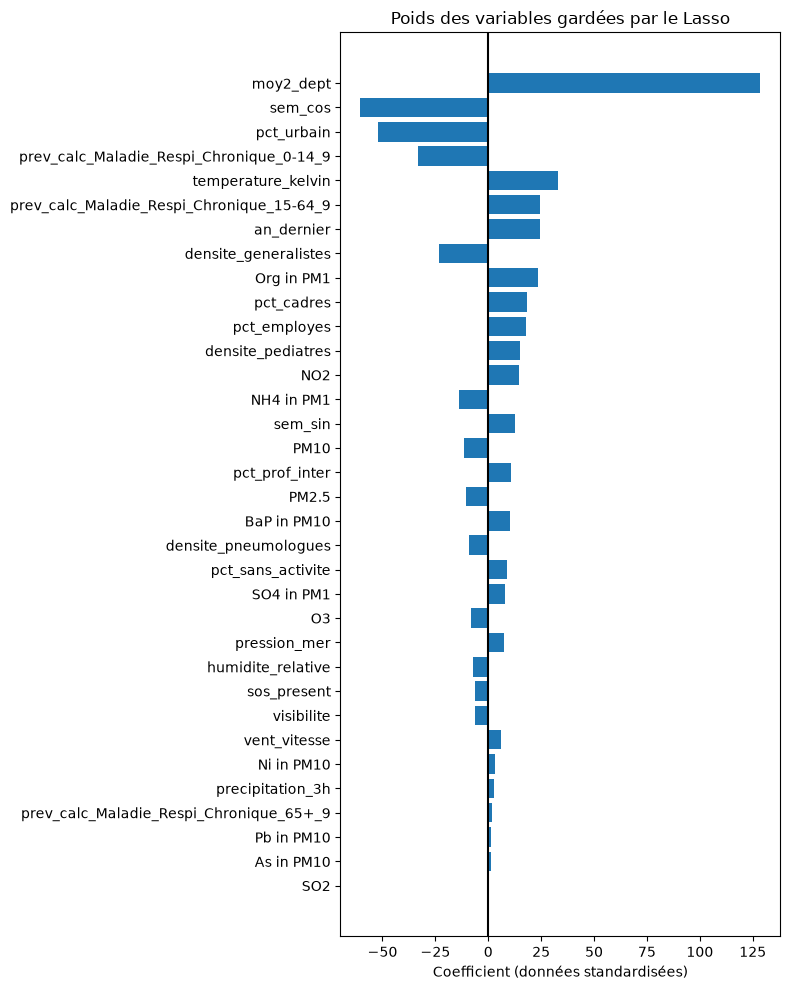

In [12]:
# poids des variables gardées par le Lasso
gardees = coefs[coefs != 0].sort_values(key=abs)

plt.figure(figsize=(8, 10))
plt.barh(gardees.index, gardees.values)
plt.axvline(0, color='black')
plt.xlabel('Coefficient (données standardisées)')
plt.title('Poids des variables gardées par le Lasso')
plt.tight_layout()
plt.show()

Le modèle s’appuie surtout sur moy2, puis sur la saison, la part urbaine, la température et le nombre de médecins généralistes. Quelques polluants comptent un peu. La prévalence chez les 0-14 ans ressort, mais 15-64 ans aussi présente avec un signe opposé : elles se compensent sûrement.

## 6. La météo en classes

La météo n'apporte rien. Peut être sous forme de combinaisons on pourrait obtenir des résultats intéressants: classification : sec ou pluie, calme ou venteux. Seuils = médianes du train.

In [13]:
seuil_pluie = train['precipitation_3h'].median()
seuil_vent = train['vent_vitesse'].median()

pluie = df['precipitation_3h'] > seuil_pluie
vent = df['vent_vitesse'] > seuil_vent

df['temps'] = 'sec_calme'
df.loc[~pluie & vent, 'temps'] = 'sec_venteux'
df.loc[pluie & ~vent, 'temps'] = 'pluie_calme'
df.loc[pluie & vent, 'temps'] = 'pluie_vent'

# nombre de semaines et taux moyen par classe
df.groupby('temps')[cible].agg(['count', 'mean']).round(0)

,count,mean
temps,,
pluie_calme,4466,784.0
pluie_vent,6170,696.0
sec_calme,5152,775.0
sec_venteux,4180,738.0


In [30]:
# une colonne 0 / 1 par classe (on en retire une, elle se déduit des autres)
classes = pd.get_dummies(df['temps'], drop_first=True).astype(int)
df[classes.columns] = classes
blocs['classes_temps'] = list(classes.columns)

# on refait le découpage pour avoir les nouvelles colonnes
train = df[df['annee'] <= 2022]
val = df[df['annee'] == 2023]
test = df[df['annee'] == 2024]

print('départ + classes :', tester(depart + ['classes_temps']))

départ + classes : {'MAE': 184.59317545248146, 'RMSE': 250.66822077335036, 'R2': 0.39946673201360794}


La répartition des classes est relativement similaire, et leur ajout n'améliore pas notre modèle.
Les semaines pluie + vent ont en moyenne moins de passages aux urgences, mais attention cette moyenne mélange départements et saisons.

## 7. Petits et grands départements

Petits départements = 1er quart des départements les moins peuplé (24 départements). J'utilise le modèle avec tous les blocs.

In [15]:
# population moyenne de chaque département, sur les années d'entraînement seulement
pop = train.groupby('code_dept')['Npop_Maladie_Respi_Chronique_tsage_9'].mean()
petits = pop[pop < pop.quantile(0.25)].index
choix = ['moy2', 'saison', 'meteo', 'pollution', 'socio', 'prevalence', 'an_dernier']
cols = sum([blocs[b] for b in choix], [])

tr = train.dropna(subset=cols + ['target'])
va = val.dropna(subset=cols + ['target'])
modele = LinearRegression().fit(tr[cols], tr['target'])
pred_va = modele.predict(va[cols])

# a. même modèle, scores séparés
masque = va['code_dept'].isin(petits)
print('Petits :', scores(va['target'][masque], pred_va[masque]))
print('Grands :', scores(va['target'][~masque], pred_va[~masque]))

Petits : {'MAE': 263.6092137285441, 'RMSE': 342.4271819863572, 'R2': 0.3350774839793734}
Grands : {'MAE': 153.32634349978767, 'RMSE': 201.98253835294204, 'R2': 0.4877826781216773}


Pour tous les départements, le modèle a un R² de 0,43. Quand on sépare les départements (petis ou grands), le score varie: il baisse à 0,34 pour les petits (avec plus d'erreurs : RMSE 342) et monte à 0,49 pour les grands (et moins d'erreurs RMSE 202). 



## 8. Test sur 2024
Tous les blocs sont gardés.

In [ ]:
tr = pd.concat([train, val]).dropna(subset=cols + ['target'])
te = test.dropna(subset=cols + ['target'])

modele = LinearRegression().fit(tr[cols], tr['target'])
pred = modele.predict(te[cols])

print('Modèle  :', scores(te['target'], pred))

# baseline : on recopie la semaine en cours
print('Recopie :', scores(te['target'], te[cible]))

masque = te['code_dept'].isin(petits)
print('Petits  :', scores(te['target'][masque], pred[masque]))
print('Grands  :', scores(te['target'][~masque], pred[~masque]))

Modèle  : {'MAE': 167.6258130610843, 'RMSE': 228.42766914640026, 'R2': 0.39582403078189043}
Recopie : {'MAE': 206.3886649817827, 'RMSE': 287.4353347957655, 'R2': 0.043364833431510874}
Petits  : {'MAE': 247.51319236425022, 'RMSE': 326.07709675927583, 'R2': 0.2635640766061307}
Grands  : {'MAE': 140.99668662669566, 'RMSE': 184.74354034324722, 'R2': 0.4827459637224568}


Le modèle fait mieux que la recopie de la semaine (RMSE 228 contre 287, R² 0,40 contre 0,04). Le score est proche de celui de la validation (o,39 contre 0,43). 
Le modèle est plus solide sur les grands départements (0,48) que sur les petits (0,26).

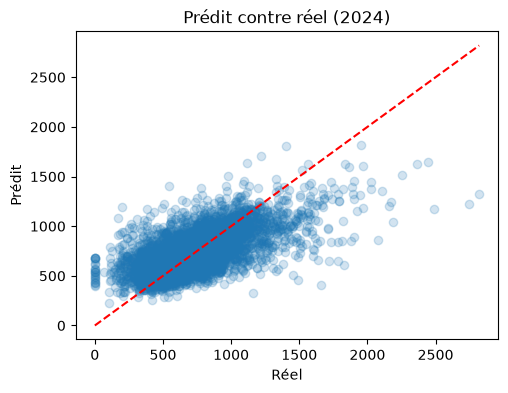

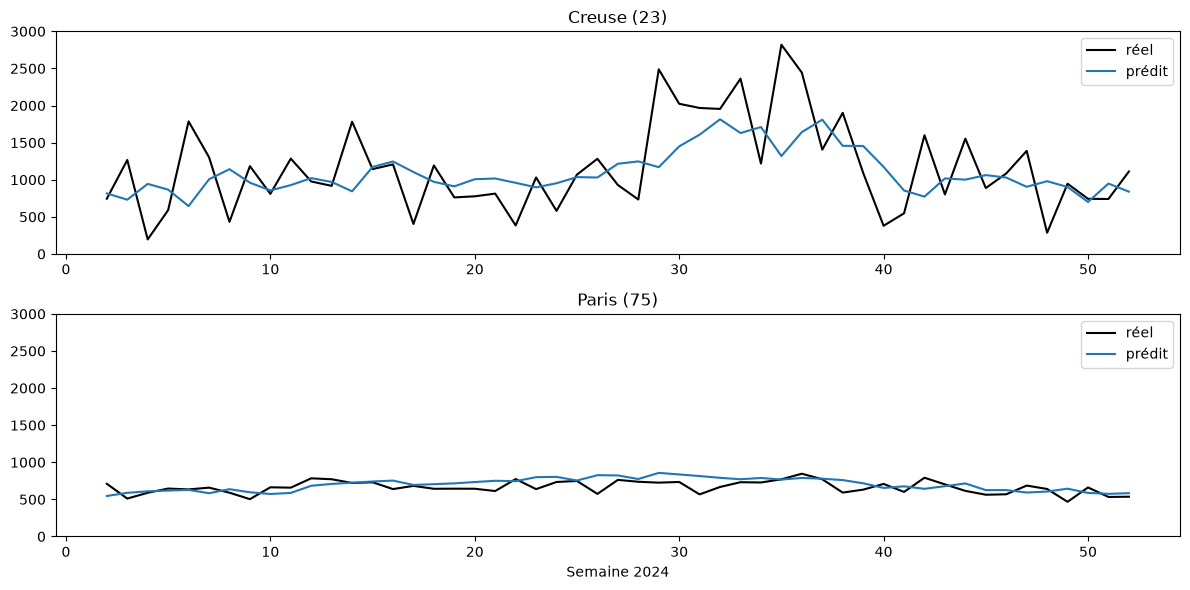

In [17]:
plt.figure(figsize=(12, 4))

# prédit contre réel
plt.subplot(1, 2, 1)
plt.scatter(te['target'], pred, alpha=0.2)
maxi = te['target'].max()
plt.plot([0, maxi], [0, maxi], color='red', linestyle='--')
plt.xlabel('Réel')
plt.ylabel('Prédit')
plt.title('Prédit contre réel (2024)')

# un petit département (Creuse) et un grand (Paris)
te_plot = te.assign(pred=pred)
depts = ['23', '75']
noms = ['Creuse (23)', 'Paris (75)']

plt.figure(figsize=(12, 6))
for i in range(2):
    plt.subplot(2, 1, i + 1)
    s = te_plot[te_plot['code_dept'] == depts[i]]
    plt.plot(s['semaine'] + 1, s['target'], color='black', label='réel')
    plt.plot(s['semaine'] + 1, s['pred'], label='prédit')
    plt.title(noms[i])
    plt.ylim(0, 3000)
    plt.legend()

plt.xlabel('Semaine 2024')
plt.tight_layout()
plt.show()


Scatterplot: nos points suivent la tendance, mais sous-estimation de certaines semaines très hautes.

Plot : Le taux de la Creuse (petit département) fluctue beaucoup plus que celui de Paris (grand département). Probablement dû aux faibles effectifs ce qui fait fortement varier le taux, ce que le modèle a du mal à prédire.

À Paris,  le taux est plus stable, le modèle le suit mieux, avec seulement une légère surestimation en fin printemps/été (semaines 20 à 33 environ).

CCL : Les petits départements font baisser les performances du modèle.
